# NB-04 — Modelo de Puigcerver treinado no BRESSAY: avaliação e inferência (Cap. 4)

O treinamento foi feito na `<vm-gpu>` (NVIDIA L4) com o pySarah (versão atual do repositório *Handwritten Text Recognition*), por `~/bressay_treino/treina_puigcerver.sh` e `retoma_puigcerver.sh`, de 18 a 19-11-2026; o `--test` rodou ao fim do treino. Os artefatos foram copiados para a dev-vm em `~/bressay_treino_resultados/` (métricas, épocas, avaliações por linha, pesos e tokenizador).

Este notebook **não treina**:
1. recalcula o CER e o WER do teste com as métricas da plataforma (`core.metrics`, as mesmas do NB-05) e compara com as do pySarah, que usa outro protocolo (minúsculas e pontuação como palavra);
2. gera as curvas de treinamento e a distribuição do CER por linha, com exemplos;
3. **inferência na CPU**: carrega os pesos copiados no ambiente do pySarah (`~/explorar_bressay/flor/.venv`), transcreve uma amostra de linhas do teste, confere com as transcrições do `--test` da VM e mede o tempo.

In [1]:
# Parâmetros
import sys
sys.path[:0] = ['lib', '..']
from pathlib import Path
ARTEFATOS = Path.home() / 'bressay_treino_resultados'
FLOR = Path.home() / 'explorar_bressay/flor'
PYTHON_FLOR = FLOR / '.venv/bin/python'
SCRIPT = Path('nb04/inferencia_puigcerver.py')
SAIDA = Path('saidas/NB-04')
SEED = 0
N_INFERENCIA = 100   # linhas do teste para a demonstração de inferência na CPU

In [2]:
import json
from datetime import datetime
import numpy as np
import pandas as pd
from IPython.display import Image, display
import nb04_puigcerver as P

SAIDA.mkdir(parents=True, exist_ok=True)
A = P.carregar(ARTEFATOS)
print('linhas de teste:', len(A['avaliacoes']), '| épocas registradas:', len(A['epocas']))
print([l for l in A['data_log'].splitlines() if 'data' in l and ':' in l])

linhas de teste: 5916 | épocas registradas: 277
['training_data            : 19,565', 'validation_data          : 4,609', 'test_data                : 5,916', 'total_data               : 30,090']


## 1. CER e WER no teste: plataforma × pySarah

In [3]:
m = P.metricas(A['avaliacoes'], A['metrics'])
df = P.tabela_linhas(A['avaliacoes'])
print(m.assign(cer=lambda x: (x.cer*100).round(2), wer=lambda x: (x.wer*100).round(2)).to_string(index=False))
print()
print('conferência: média do CER do pySarah recalculada a partir das linhas:', round(df.cer_pysarah.mean()*100, 2), '%')

                  protocolo  cer   wer
 plataforma, global (micro) 8.96 24.93
plataforma, média por linha 8.70 24.77
   pySarah, média por linha 8.70 21.82

conferência: média do CER do pySarah recalculada a partir das linhas: 8.7 %


O CER praticamente coincide entre os protocolos; o WER do pySarah é menor porque ele separa cada sinal de pontuação como uma palavra (quase sempre reconhecida corretamente) e ignora maiúsculas. O artigo do BRESSAY usa o código do mesmo autor, então a comparação com o artigo é feita com o protocolo do pySarah; a comparação com os motores do Cap. 5, com o da plataforma.

## 2. Curvas de treinamento

épocas: 277 | melhor (menor val_dist): 257 (0.0817) | troca da taxa em: [206]


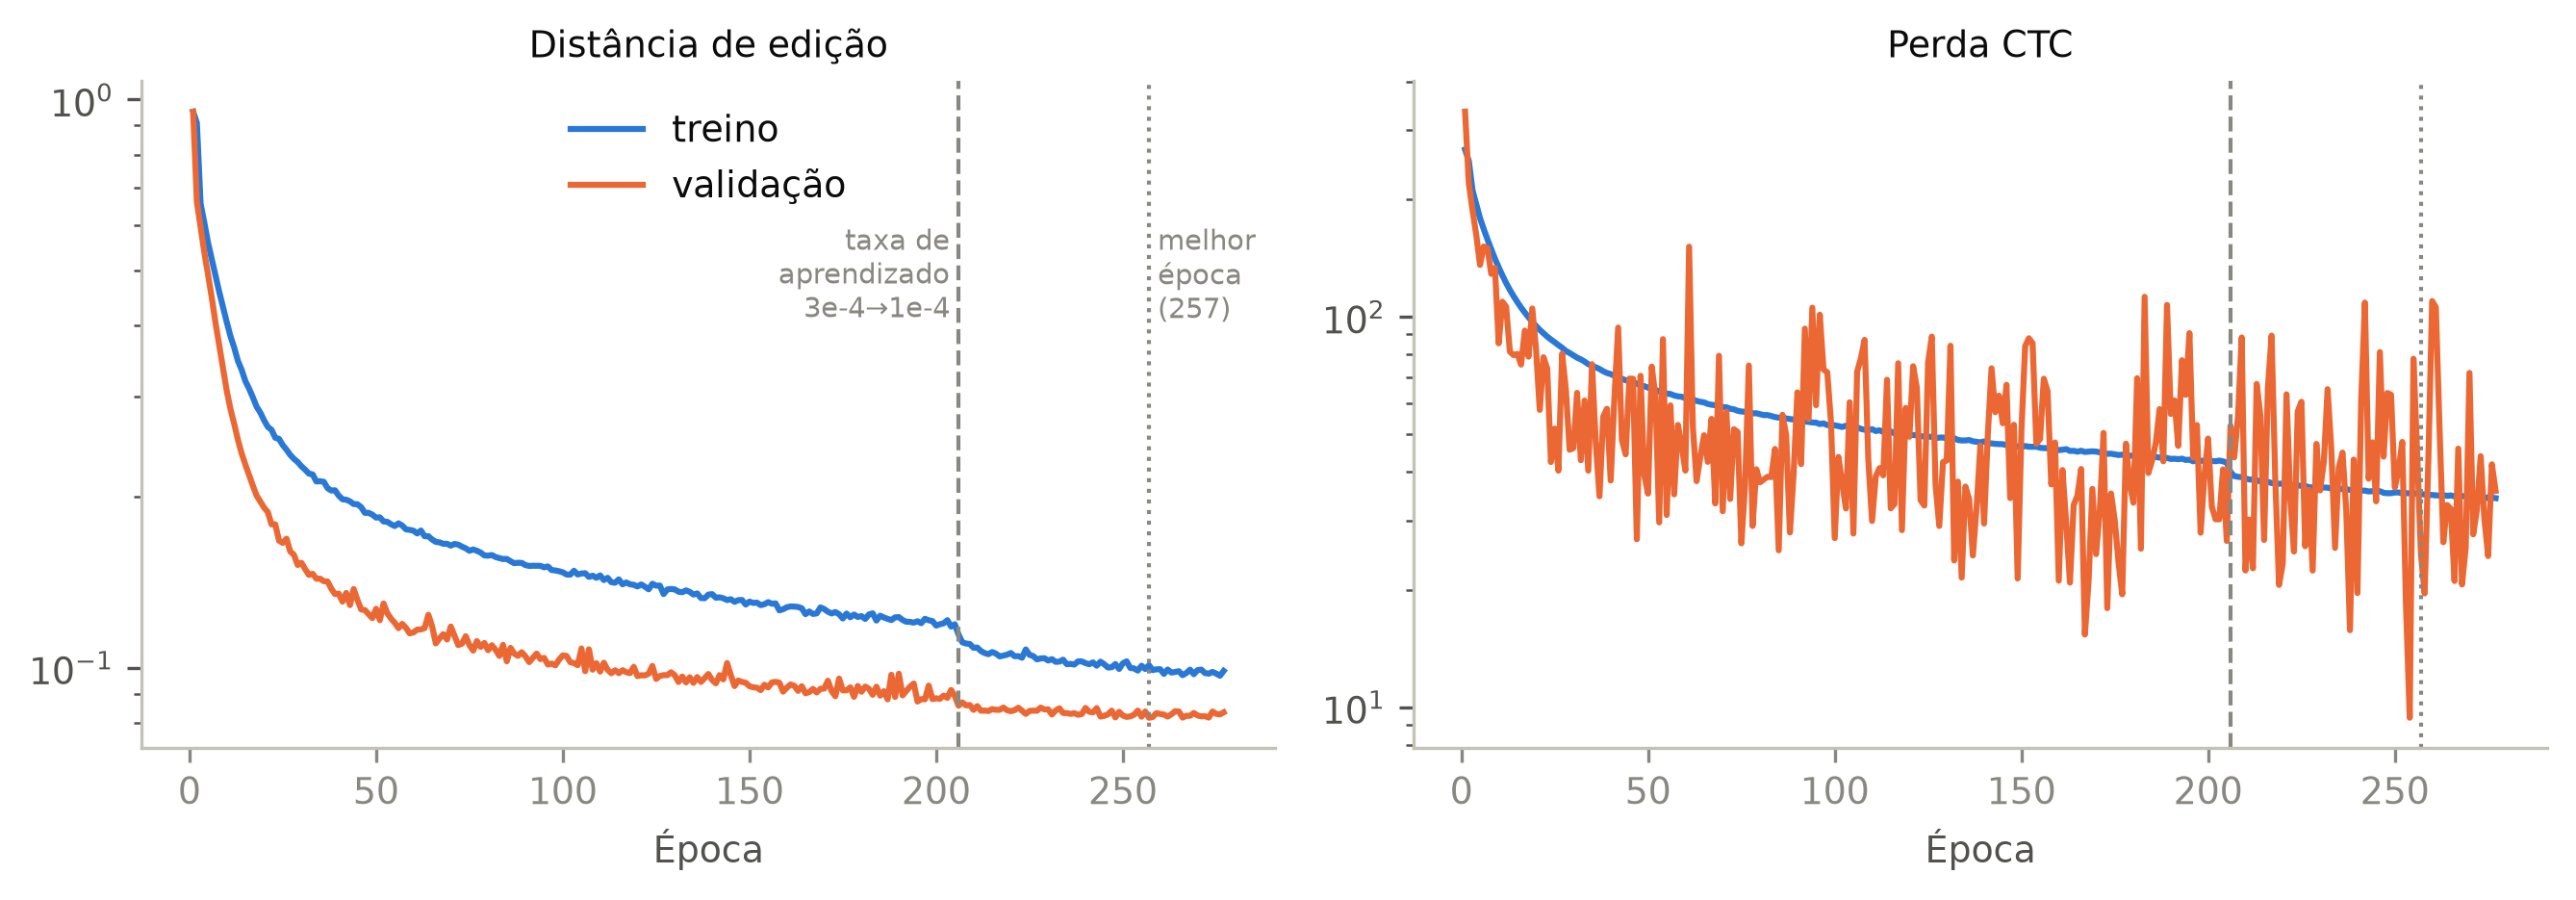

In [4]:
melhor, troca = P.figura_curvas(A['epocas'], SAIDA / 'fig_curvas_treino.png')
ep = A['epocas']
print('épocas:', int(ep.epoch.max()), '| melhor (menor val_dist):', melhor, f"({ep.val_dist.min():.4f})", '| troca da taxa em:', troca)
display(Image(SAIDA / 'fig_curvas_treino.png', width=850))

## 3. Distribuição do CER por linha e exemplos

quantis do CER por linha (%): {0.1: np.float64(0.0), 0.25: np.float64(2.3), 0.5: np.float64(5.6), 0.75: np.float64(11.5), 0.9: np.float64(20.3)}
linhas sem nenhum erro: 646 (10.9%)
linhas com CER > 30%: 232 (3.9%)


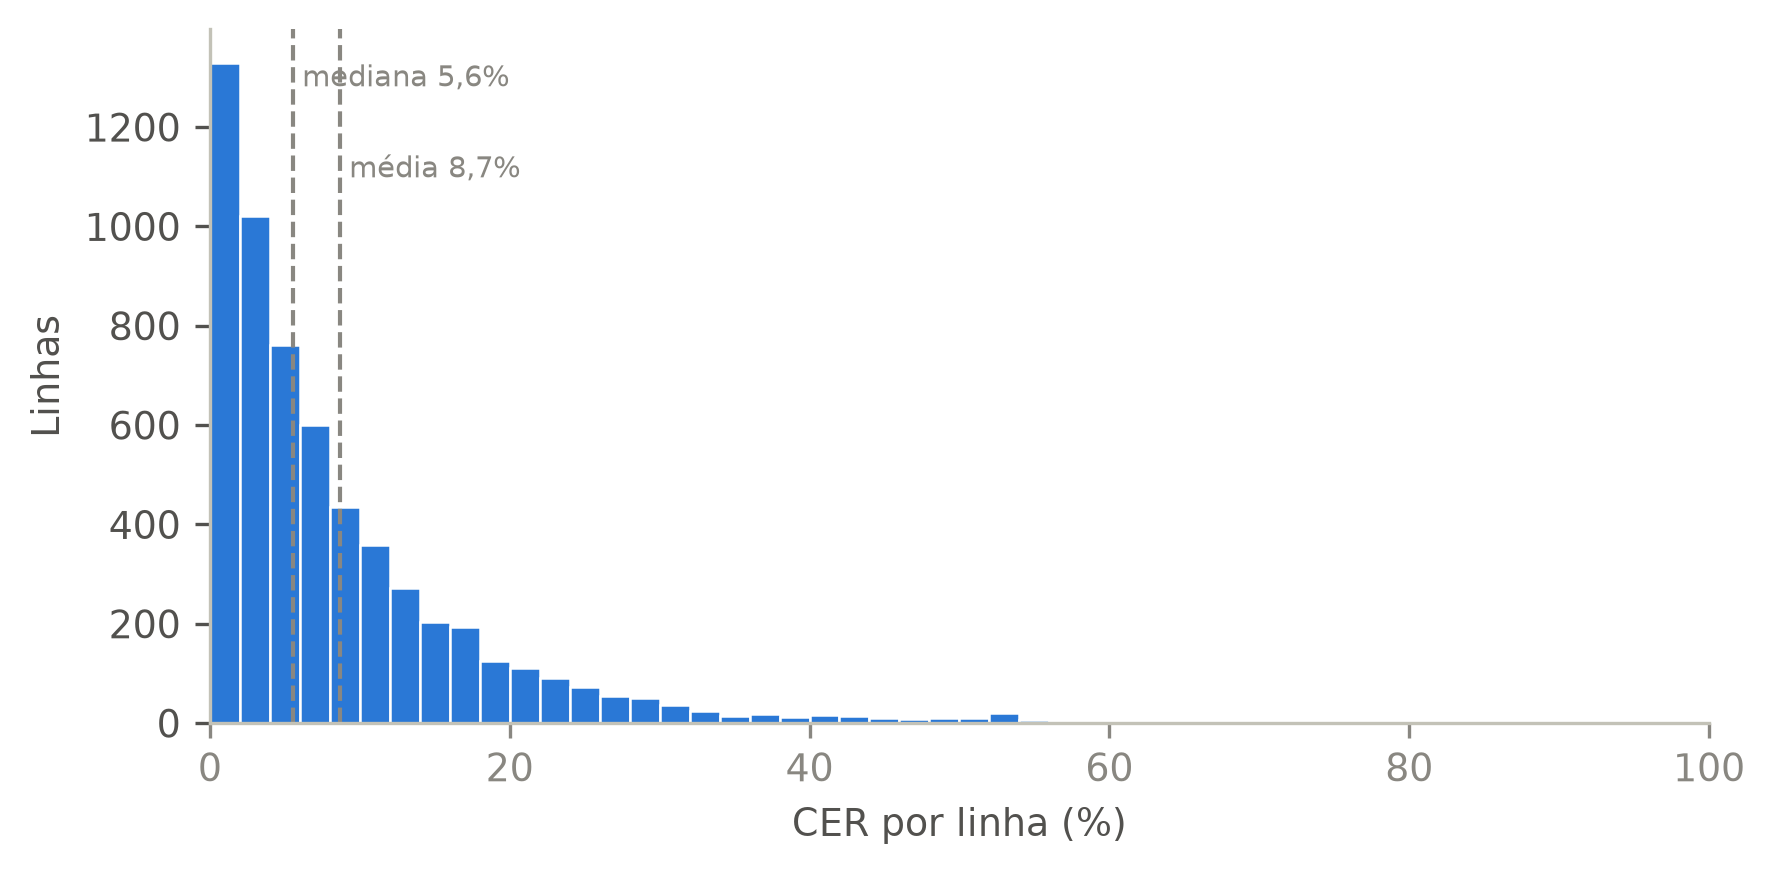

In [5]:
P.figura_cer_linhas(df, SAIDA / 'fig_cer_por_linha.png')
q = (df.cer*100).quantile([.1, .25, .5, .75, .9]).round(1)
print('quantis do CER por linha (%):', dict(q))
print('linhas sem nenhum erro:', int((df.cer == 0).sum()), f"({(df.cer == 0).mean()*100:.1f}%)")
print('linhas com CER > 30%:', int((df.cer > .3).sum()), f"({(df.cer > .3).mean()*100:.1f}%)")
display(Image(SAIDA / 'fig_cer_por_linha.png', width=600))

In [6]:
# Exemplos: uma linha perto de cada quantil (sem escolha manual)
pd.set_option('display.max_colwidth', 120)
ex = pd.concat([df.iloc[(df.cer - df.cer.quantile(qq)).abs().argsort()[:1]] for qq in (.1, .5, .9)])
ex[['image', 'cer', 'referencia', 'predicao']].assign(cer=lambda x: (x.cer*100).round(1))

,image,cer,referencia,predicao
3531,datasets/bressay/data/lines/0951-036/0951-036-04-05.png,0.0,"enças mentais no Brasil, a serem divulgadas nas mídias sociais, a fim de contribuir","enças mentais no Brasil, a serem divulgadas nas mídias sociais, a fim de contribuir"
480,datasets/bressay/data/lines/8626-074/8626-074-02-07.png,5.6,"túrbio é automaticamente tido como motivo de vergonha. Dessa forma, esse","túsbio é automaticamente tido como protivo de sergonha. Dessa forma, esse"
432,datasets/bressay/data/lines/7572-028/7572-028-02-03.png,20.3,"viços mais elaborados, como pipocas com corbeturas caras e atendentes nas poltronas. Dessa forma, os valores de ingr...","vaços mais cabocados, como píbcas com coetivas eares e arimentes nas portemas. Dessa forta, os vaores de inresso ao"


## 4. Inferência na CPU (dev-vm)

In [7]:
rng = np.random.default_rng(SEED)
idx = sorted(rng.choice(len(A['avaliacoes']), size=N_INFERENCIA, replace=False).tolist())
linhas = [{'image': A['avaliacoes'][i]['image'], 'text': A['avaliacoes'][i]['text']} for i in idx]
inf = P.inferir(linhas, SAIDA / 'inferencia_cpu.json', PYTHON_FLOR, SCRIPT, ARTEFATOS, FLOR)
vm = {x['image']: x['predictions'][0]['text'] for x in A['avaliacoes']}
iguais = sum(l['predicao'] == vm[l['image']] for l in inf['linhas'])
dif_cer = np.mean([P.cer(l['predicao'], vm[l['image']]) for l in inf['linhas']])
print(f"TensorFlow {inf['tf']}, {inf['dispositivo']} ({inf['cpus']} núcleos), feixe {inf['beam_width']}, lote {inf['batch_size']}")
print(f"carga do modelo: {inf['tempo_carga_s']:.1f} s | inferência: {inf['tempo_inferencia_s']:.1f} s para {inf['n']} linhas = {inf['tempo_por_linha_s']:.2f} s/linha")
print(f"transcrições idênticas às do --test na GPU: {iguais} de {inf['n']}; diferença média (CER entre as duas): {dif_cer*100:.2f}%")

TensorFlow 2.19.0, CPU (4 núcleos), feixe 32, lote 16
carga do modelo: 5.4 s | inferência: 37.1 s para 100 linhas = 0.37 s/linha
transcrições idênticas às do --test na GPU: 100 de 100; diferença média (CER entre as duas): 0.00%


Pequenas diferenças entre CPU e GPU são esperadas: a aritmética de ponto flutuante difere entre os dispositivos e pode mudar uma escolha da busca em feixe.

## Saídas para o texto

In [8]:
(SAIDA / 'tabela_teste.tex').write_text(P.tabela_tex(m))
df.to_csv(SAIDA / 'cer_wer_por_linha.csv', index=False)
manifest = {'notebook': 'NB-04', 'data': datetime.now().isoformat(timespec='seconds'), 'artefatos': str(ARTEFATOS),
            'run_id': '5a5a8f579cb14ed8960c0f888ea99b83', 'linhas_teste': len(df),
            'metricas': m.to_dict(orient='records'), 'melhor_epoca': melhor, 'epocas': int(ep.epoch.max()),
            'inferencia_cpu': {k: inf[k] for k in ('tf', 'dispositivo', 'cpus', 'beam_width', 'batch_size', 'n',
                                                    'tempo_carga_s', 'tempo_inferencia_s', 'tempo_por_linha_s')},
            'inferencia_iguais_gpu': iguais, 'seed': SEED}
(SAIDA / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=1))
sorted(p.name for p in SAIDA.iterdir())

['cer_wer_por_linha.csv',
 'fig_cer_por_linha.png',
 'fig_curvas_treino.png',
 'inferencia_cpu.json',
 'inferencia_cpu_entrada.json',
 'manifest.json',
 'tabela_teste.tex']